# TP2 - Segmentación de clientes por valor (RFM)

Actividades 0 a 3. El proyecto parte de la migración de Sakila realizada en TP1: los nombres físicos en español se resuelven únicamente desde `esquema.py`. Ejecutar de arriba hacia abajo con el kernel de `venv_tp2` y guardar las salidas visibles.


In [19]:
import sys
from pathlib import Path

RAIZ = Path.cwd().resolve()
if not (RAIZ / "config_conexion.py").exists():
    RAIZ = RAIZ.parent
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import pandas as pd
from config_conexion import engine
from esquema import columna_sql, get_tabla_espanol, renderizar_sql, tabla_sql

# El código conserva nombres canónicos; toda salida visible se presenta en español.
ETIQUETAS = {
    "canonical_table": "tabla_canónica",
    "local_table_name": "tabla_en_SQL_Server",
    "source_mysql_rows": "filas_origen_MySQL",
    "sql_server_rows": "filas_SQL_Server",
    "difference": "diferencia",
    "customer_id": "id_cliente",
    "customer_name": "nombre_cliente",
    "recency_days": "recencia_días",
    "rental_frequency": "frecuencia_alquileres",
    "monetary_amount": "monto_total",
    "R_qcut": "R (qcut)",
    "F_qcut": "F (qcut)",
    "M_qcut": "M (qcut)",
    "R_ntile": "R (NTILE)",
    "F_ntile": "F (NTILE)",
    "M_ntile": "M (NTILE)",
    "Segmento_RFM": "segmento_RFM",
}
ETIQUETAS_CONTROLES = {
    "duplicate_customers": "clientes_duplicados",
    "payments_without_rental": "pagos_sin_alquiler",
    "amount_payments_without_rental": "monto_pagos_sin_alquiler",
    "customers_without_payment": "clientes_sin_pago",
    "negative_payments": "pagos_negativos",
}

def vista(tabla):
    """Devuelve una copia para mostrar, con encabezados en español."""
    return tabla.rename(columns=ETIQUETAS)

# Actividad 0: la plantilla usa nombres canónicos; esquema.py los convierte a nombres locales.
plantilla_reconciliacion = (RAIZ / "sql" / "reconciliacion.sql").read_text(encoding="utf-8")
query_reconciliacion = renderizar_sql(plantilla_reconciliacion)
df_reconciliacion = pd.read_sql_query(query_reconciliacion, con=engine)
df_reconciliacion.insert(1, "local_table_name", df_reconciliacion["canonical_table"].map(get_tabla_espanol))
display(vista(df_reconciliacion))

differences = df_reconciliacion.query("difference != 0")
if differences.empty:
    print("Reconciliación correcta.")
else:
    print("Diferencias que deben documentarse en el diagnóstico:")
    display(vista(differences))
    difference_pagos = differences.query("canonical_table == 'payment'")
    if not difference_pagos.empty:
        print(
            "Diagnóstico: SQL Server tiene 5 pagos menos que el volcado Sakila. "
            "Los controles de la Actividad 2 verifican si esa diferencia corresponde "
            "a pagos sin alquiler que no se trasladaron en la migración."
        )

# Los nombres físicos se resuelven exclusivamente desde esquema.py.
T = {x: tabla_sql(x) for x in ("customer", "rental", "payment")}
C = {
    "customer": {x: columna_sql("customer", x) for x in ("customer_id", "first_name", "last_name")},
    "rental": {x: columna_sql("rental", x) for x in ("rental_id", "customer_id", "rental_date")},
    "payment": {x: columna_sql("payment", x) for x in ("payment_id", "customer_id", "rental_id", "amount")},
}


,tabla_canónica,tabla_en_SQL_Server,filas_origen_MySQL,filas_SQL_Server,diferencia
0,actor,actor,200,200,0
1,address,direccion,603,603,0
2,category,categoria,16,16,0
3,city,ciudad,600,600,0
4,country,pais,109,109,0
5,customer,cliente,599,599,0
6,film,pelicula,1000,1000,0
7,film_actor,pelicula_actor,5462,5462,0
8,film_category,pelicula_categoria,1000,1000,0
9,film_text,pelicula_texto,1000,1000,0


Diferencias que deben documentarse en el diagnóstico:


,tabla_canónica,tabla_en_SQL_Server,filas_origen_MySQL,filas_SQL_Server,diferencia
12,payment,pago,16049,16044,-5


Diagnóstico: SQL Server tiene 5 pagos menos que el volcado Sakila. Los controles de la Actividad 2 verifican si esa diferencia corresponde a pagos sin alquiler que no se trasladaron en la migración.


## Actividad 1 - Conjunto de trabajo y quintiles RFM

SQL Server resuelve el conjunto agregado; pandas replica la métrica para verificar el resultado. Los empates se desempatan por `customer_id`. Se calculan tanto `qcut` como `NTILE(5)` y se deja evidencia de cualquier difference de borde.


In [20]:
# Actividad 1: carga del conjunto RFM producido por SQL Server.
plantilla_rfm = (RAIZ / "sql" / "conjunto_trabajo.sql").read_text(encoding="utf-8")
query_rfm = renderizar_sql(plantilla_rfm)
df_rfm = pd.read_sql_query(query_rfm, con=engine)

# Se ordena por valor e customer_id para que los empates se asignen de forma reproducible.
def puntuar_quintiles(frame, columna, etiquetas):
    ordenado = frame.sort_values([columna, "customer_id"], kind="stable")
    rangos = ordenado[columna].rank(method="first")
    puntajes = pd.qcut(rangos, q=5, labels=etiquetas).astype(int)
    return pd.Series(puntajes.to_numpy(), index=ordenado.index).reindex(frame.index).astype(int)

if df_rfm["recency_days"].isna().any():
    df_rfm["recency_days"] = df_rfm["recency_days"].fillna(df_rfm["recency_days"].max() + 1)

df_rfm["R_qcut"] = puntuar_quintiles(df_rfm, "recency_days", [5, 4, 3, 2, 1])
df_rfm["F_qcut"] = puntuar_quintiles(df_rfm, "rental_frequency", [1, 2, 3, 4, 5])
df_rfm["M_qcut"] = puntuar_quintiles(df_rfm, "monetary_amount", [1, 2, 3, 4, 5])
df_rfm["Segmento_RFM"] = (
    df_rfm["R_qcut"].astype(str)
    + df_rfm["F_qcut"].astype(str)
    + df_rfm["M_qcut"].astype(str)
)
display(vista(df_rfm.head(10)))


,id_cliente,nombre_cliente,recencia_días,frecuencia_alquileres,monto_total,R (qcut),F (qcut),M (qcut),segmento_RFM
0,1,MARY SMITH,176,32,118.68,2,5,4,254
1,2,PATRICIA JOHNSON,175,27,128.73,4,3,4,434
2,3,LINDA WILLIAMS,175,26,135.74,4,3,5,435
3,4,BARBARA JONES,175,22,81.78,4,1,1,411
4,5,ELIZABETH BROWN,0,38,144.62,5,5,5,555
5,6,JENNIFER DAVIS,175,28,93.72,4,3,2,432
6,7,MARIA MILLER,177,33,151.67,1,5,5,155
7,8,SUSAN WILSON,175,24,92.76,4,2,2,422
8,9,MARGARET MOORE,0,23,89.77,5,1,1,511
9,10,DOROTHY TAYLOR,176,25,99.75,2,2,2,222


In [21]:
# Comparación de discretización NTILE(5) en T-SQL vs pd.qcut en pandas.
# El orden secundario customer_id hace reproducible el tratamiento de empates.
query_ntile = f"""
WITH FechaMax AS (
    SELECT MAX({C['rental']['rental_date']}) AS max_fecha FROM {T['rental']}
),
MetricasRFM AS (
    SELECT
        c.{C['customer']['customer_id']} AS customer_id,
        DATEDIFF(day, MAX(a.{C['rental']['rental_date']}), (SELECT max_fecha FROM FechaMax)) AS recency_days,
        COUNT(DISTINCT a.{C['rental']['rental_id']}) AS rental_frequency,
        COALESCE(SUM(p.{C['payment']['amount']}), 0) AS monetary_amount
    FROM {T['customer']} AS c
    LEFT JOIN {T['rental']} AS a
        ON a.{C['rental']['customer_id']} = c.{C['customer']['customer_id']}
    LEFT JOIN {T['payment']} AS p
        ON a.{C['rental']['rental_id']} = p.{C['payment']['rental_id']}
    GROUP BY c.{C['customer']['customer_id']}
)
SELECT
    customer_id,
    NTILE(5) OVER (ORDER BY recency_days ASC, customer_id ASC) AS R_ntile,
    NTILE(5) OVER (ORDER BY rental_frequency ASC, customer_id ASC) AS F_ntile,
    NTILE(5) OVER (ORDER BY monetary_amount ASC, customer_id ASC) AS M_ntile
FROM MetricasRFM;
"""

df_ntile = pd.read_sql_query(query_ntile, con=engine)
df_ntile["R_ntile"] = 6 - df_ntile["R_ntile"]  # 5 = cliente más reciente.
df_comparativa = df_rfm.merge(df_ntile, on="customer_id", validate="one_to_one")

# qcut y NTILE no distribuyen igual el resto cuando n no es múltiplo de 5.
# Esta función replica exactamente el reparto de NTILE para dejar el control verificable.
def puntuar_como_ntile(frame, columna, invertir=False):
    ordenado = frame.sort_values([columna, "customer_id"], kind="stable").copy()
    n = len(ordenado)
    puntaje = (pd.Series(range(n), index=ordenado.index) * 5 // n + 1).astype(int)
    if invertir:
        puntaje = 6 - puntaje
    return puntaje.reindex(frame.index).astype(int)

for columna, destino, invertir in (
    ("recency_days", "R_pandas_ntile", True),
    ("rental_frequency", "F_pandas_ntile", False),
    ("monetary_amount", "M_pandas_ntile", False),
):
    df_comparativa[destino] = puntuar_como_ntile(df_comparativa, columna, invertir)

filas_resumen = []
for letra in "RFM":
    qcut = f"{letra}_qcut"
    ntile = f"{letra}_ntile"
    equivalente = f"{letra}_pandas_ntile"
    filas_resumen.append({
        "métrica": letra,
        "coincidencia qcut vs NTILE (%)": (df_comparativa[qcut] == df_comparativa[ntile]).mean() * 100,
        "coincidencia pandas equivalente vs NTILE (%)": (df_comparativa[equivalente] == df_comparativa[ntile]).mean() * 100,
        "casos frontera qcut": int((df_comparativa[qcut] != df_comparativa[ntile]).sum()),
    })
resumen_quintiles = pd.DataFrame(filas_resumen)
display(resumen_quintiles)

casos_frontera = df_comparativa.loc[
    (df_comparativa[["R_qcut", "F_qcut", "M_qcut"]].to_numpy() != df_comparativa[["R_ntile", "F_ntile", "M_ntile"]].to_numpy()).any(axis=1),
    ["customer_id", "recency_days", "rental_frequency", "monetary_amount", "R_qcut", "R_ntile", "F_qcut", "F_ntile", "M_qcut", "M_ntile"],
]
display(vista(casos_frontera))
assert (resumen_quintiles["coincidencia pandas equivalente vs NTILE (%)"] == 100).all()
print(
    "Interpretación: qcut se ejecuta como técnica solicitada. Con 599 clientes, "
    "el reparto del resto difiere de NTILE en límites de quintil; la segunda "
    "puntuación pandas replica la regla de NTILE y coincide exactamente."
)


,métrica,coincidencia qcut vs NTILE (%),coincidencia pandas equivalente vs NTILE (%),casos frontera qcut
0,R,99.66611,100.0,2
1,F,99.66611,100.0,2
2,M,99.66611,100.0,2


,id_cliente,recencia_días,frecuencia_alquileres,monto_total,R (qcut),R (NTILE),F (qcut),F (NTILE),M (qcut),M (NTILE)
220,221,176,28,132.72,2,2,4,3,4,4
264,265,176,29,133.71,1,2,4,4,5,4
339,340,176,31,119.69,1,1,5,4,4,4
444,445,175,26,102.74,2,3,3,3,2,2
445,446,175,31,116.69,2,2,5,5,4,3


Interpretación: qcut se ejecuta como técnica solicitada. Con 599 clientes, el reparto del resto difiere de NTILE en límites de quintil; la segunda puntuación pandas replica la regla de NTILE y coincide exactamente.


## Actividad 1 - Comparación SQL contra pandas

La misma métrica se reconstruye a partir del detalle crudo. Los tiempos incluyen extracción y cálculo para cada enfoque.


In [22]:
import time
from pandas.testing import assert_frame_equal

inicio_sql = time.perf_counter()
df_sql_tiempo = pd.read_sql_query(query_rfm, con=engine)
tiempo_sql = time.perf_counter() - inicio_sql

inicio_pandas = time.perf_counter()
query_detalle = f"""
SELECT c.{C['customer']['customer_id']} AS customer_id,
       CONCAT(c.{C['customer']['first_name']}, ' ', c.{C['customer']['last_name']}) AS customer_name,
       a.{C['rental']['rental_id']} AS rental_id,
       a.{C['rental']['rental_date']} AS rental_date,
       p.{C['payment']['amount']} AS amount
FROM {T['customer']} AS c
LEFT JOIN {T['rental']} AS a ON a.{C['rental']['customer_id']} = c.{C['customer']['customer_id']}
LEFT JOIN {T['payment']} AS p ON p.{C['payment']['rental_id']} = a.{C['rental']['rental_id']};
"""
df_detalle = pd.read_sql_query(query_detalle, con=engine)
fecha_maxima = df_detalle["rental_date"].max()
df_pandas = (df_detalle.groupby(["customer_id", "customer_name"], as_index=False)
             .agg(last_rental_date=("rental_date", "max"),
                  rental_frequency=("rental_id", "nunique"),
                  monetary_amount=("amount", "sum")))
df_pandas["monetary_amount"] = df_pandas["monetary_amount"].fillna(0)
# SQL Server DATEDIFF(day, ...) compara fechas de calendario, no períodos completos de 24 horas.
# Normalizar a medianoche reproduce exactamente esa semántica en pandas.
df_pandas["recency_days"] = (
    fecha_maxima.normalize() - df_pandas["last_rental_date"].dt.normalize()
).dt.days
tiempo_pandas = time.perf_counter() - inicio_pandas

esperado = df_sql_tiempo[["customer_id", "recency_days", "rental_frequency", "monetary_amount"]].sort_values("customer_id")
calculado = df_pandas[["customer_id", "recency_days", "rental_frequency", "monetary_amount"]].sort_values("customer_id")
assert_frame_equal(esperado.reset_index(drop=True), calculado.reset_index(drop=True), check_dtype=False, atol=0.01)
display(pd.DataFrame({"enfoque": ["T-SQL agregado", "pandas sobre detalle crudo"], "segundos": [tiempo_sql, tiempo_pandas]}))
print("La métrica RFM coincide en ambos enfoques.")


,enfoque,segundos
0,T-SQL agregado,0.074732
1,pandas sobre detalle crudo,0.331353


La métrica RFM coincide en ambos enfoques.


## Actividad 2 - Perfilado y controles de calidad

Los atípicos se detectan por IQR y se conservan salvo evidencia de error, ya que pueden ser clientes de alto valor.


In [23]:
print(f"Dimensión del conjunto: {df_rfm.shape[0]} clientes y {df_rfm.shape[1]} columnas")
display(vista(df_rfm.sample(min(5, len(df_rfm)), random_state=42)))

def tipo_en_espanol(serie):
    if pd.api.types.is_integer_dtype(serie):
        return "entero"
    if pd.api.types.is_float_dtype(serie):
        return "decimal"
    if pd.api.types.is_datetime64_any_dtype(serie):
        return "fecha y hora"
    return "texto"

perfil_columnas = pd.DataFrame({
    "tipo_de_dato": [tipo_en_espanol(df_rfm[columna]) for columna in df_rfm.columns],
    "valores_no_nulos": df_rfm.notna().sum().to_numpy(),
    "valores_nulos": df_rfm.isna().sum().to_numpy(),
    "porcentaje_nulos": df_rfm.isna().mean().mul(100).round(2).to_numpy(),
}, index=[ETIQUETAS.get(columna, columna) for columna in df_rfm.columns])
perfil_columnas.index.name = "columna"
print("Estructura y calidad de las columnas:")
display(perfil_columnas)

print("Duplicados por id_cliente:", df_rfm["customer_id"].duplicated().sum())
estadisticas = df_rfm[["recency_days", "rental_frequency", "monetary_amount"]].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99])
etiquetas_estadisticas = {
    "count": "cantidad",
    "mean": "promedio",
    "std": "desvío_estándar",
    "min": "mínimo",
    "max": "máximo",
    "1%": "percentil_1%",
    "5%": "percentil_5%",
    "25%": "percentil_25%",
    "50%": "mediana",
    "75%": "percentil_75%",
    "95%": "percentil_95%",
    "99%": "percentil_99%",
}
estadisticas.index = [etiquetas_estadisticas.get(str(indice), str(indice)) for indice in estadisticas.index]
estadisticas.index.name = "estadístico"
display(vista(estadisticas))

q1, q3 = df_rfm["monetary_amount"].quantile([.25, .75])
iqr = q3 - q1
limite_inferior, limite_superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr
atipicos = df_rfm.query("monetary_amount < @limite_inferior or monetary_amount > @limite_superior")
print(f"IQR monetario: Q1=${q1:.2f}, Q3=${q3:.2f}, límites=(${limite_inferior:.2f}, ${limite_superior:.2f})")
print(f"Atípicos de monto: {len(atipicos)} ({len(atipicos) / len(df_rfm):.1%})")
display(vista(atipicos[["customer_id", "customer_name", "rental_frequency", "monetary_amount"]]))
print("Decisión: se conservan los atípicos porque son clientes de alto valor plausibles, no errores negativos o duplicados.")

# Se recuperan las mismas entidades para contrastar controles SQL Server vs pandas.
query_pagos = f"""
SELECT p.{C['payment']['payment_id']} AS payment_id,
       p.{C['payment']['customer_id']} AS customer_id,
       p.{C['payment']['rental_id']} AS rental_id,
       p.{C['payment']['amount']} AS amount
FROM {T['payment']} AS p;
"""
df_pagos = pd.read_sql_query(query_pagos, con=engine)

query_controles = f"""
SELECT
    (SELECT COUNT(*) FROM (
        SELECT c.{C['customer']['customer_id']}
        FROM {T['customer']} AS c
        GROUP BY c.{C['customer']['customer_id']}
        HAVING COUNT(*) > 1
    ) AS repetidos) AS duplicate_customers,
    SUM(CASE WHEN p.{C['payment']['rental_id']} IS NULL THEN 1 ELSE 0 END) AS payments_without_rental,
    COALESCE(SUM(CASE WHEN p.{C['payment']['rental_id']} IS NULL THEN p.{C['payment']['amount']} ELSE 0 END), 0) AS amount_payments_without_rental,
    (SELECT COUNT(*) FROM {T['customer']} AS c
     LEFT JOIN {T['payment']} AS p2
       ON p2.{C['payment']['customer_id']} = c.{C['customer']['customer_id']}
     WHERE p2.{C['payment']['payment_id']} IS NULL) AS customers_without_payment,
    SUM(CASE WHEN p.{C['payment']['amount']} < 0 THEN 1 ELSE 0 END) AS negative_payments,
    SUM(CASE WHEN p.{C['payment']['rental_id']} IS NOT NULL
                  AND p.{C['payment']['customer_id']} <> a.{C['rental']['customer_id']}
             THEN 1 ELSE 0 END) AS payment_customer_mismatch
FROM {T['payment']} AS p
LEFT JOIN {T['rental']} AS a
    ON a.{C['rental']['rental_id']} = p.{C['payment']['rental_id']};
"""
controles_sql = pd.read_sql_query(query_controles, con=engine).iloc[0]
controles_pandas = pd.Series({
    "duplicate_customers": int(df_rfm["customer_id"].duplicated().sum()),
    "payments_without_rental": int(df_pagos["rental_id"].isna().sum()),
    "amount_payments_without_rental": float(df_pagos.loc[df_pagos["rental_id"].isna(), "amount"].sum()),
    "customers_without_payment": int(len(set(df_rfm["customer_id"]) - set(df_pagos["customer_id"]))),
    "negative_payments": int((df_pagos["amount"] < 0).sum()),
})
comparacion_controles = pd.DataFrame({"SQL Server": controles_sql[controles_pandas.index], "pandas": controles_pandas})
comparacion_controles["coincide"] = comparacion_controles["SQL Server"].astype(float).round(2).eq(comparacion_controles["pandas"].astype(float).round(2))
comparacion_controles.index = comparacion_controles.index.map(ETIQUETAS_CONTROLES)
comparacion_controles = comparacion_controles.rename(columns={"pandas": "Pandas", "coincide": "coincide"})
display(comparacion_controles)
assert comparacion_controles["coincide"].all()

print("Regla de negocio 1 — no se admiten montos negativos:", int(controles_sql["negative_payments"]))
print("Regla de negocio 2 — la recencia no puede ser negativa:", int((df_rfm["recency_days"] < 0).sum()))
print("Regla de integridad — pago asociado a otro cliente:", int(controles_sql["payment_customer_mismatch"]))
if controles_sql["payments_without_rental"] == 0 and not differences.query("canonical_table == 'payment'").empty:
    print("Conclusión de migración: los 5 pagos faltantes son consistentes con pagos sin alquiler que no llegaron a SQL Server; el conjunto RFM no los usa.")


Dimensión del conjunto: 599 clientes y 9 columnas


,id_cliente,nombre_cliente,recencia_días,frecuencia_alquileres,monto_total,R (qcut),F (qcut),M (qcut),segmento_RFM
110,111,CARMEN OWENS,0,26,97.74,5,3,2,532
419,420,JACOB LANCE,175,21,79.79,3,1,1,311
564,565,JAIME NETTLES,175,29,126.71,2,4,4,244
77,78,LORI WOOD,175,31,141.69,4,4,5,445
181,182,RENEE LANE,176,26,97.74,2,3,2,232


Estructura y calidad de las columnas:


,tipo_de_dato,valores_no_nulos,valores_nulos,porcentaje_nulos
columna,,,,
id_cliente,entero,599,0,0.0
nombre_cliente,texto,599,0,0.0
recencia_días,entero,599,0,0.0
frecuencia_alquileres,entero,599,0,0.0
monto_total,decimal,599,0,0.0
R (qcut),entero,599,0,0.0
F (qcut),entero,599,0,0.0
M (qcut),entero,599,0,0.0
segmento_RFM,texto,599,0,0.0


Duplicados por id_cliente: 0


...

IQR monetario: Q1=$94.78, Q3=$128.70, límites=($43.91, $179.58)
Atípicos de monto: 6 (1.0%)


,id_cliente,nombre_cliente,frecuencia_alquileres,monto_total
136,137,RHONDA KENNEDY,39,194.61
143,144,CLARA SHAW,42,195.58
147,148,ELEANOR HUNT,46,216.54
177,178,MARION SNYDER,39,194.61
458,459,TOMMY COLLAZO,38,186.62
525,526,KARL SEAL,45,221.55


Decisión: se conservan los atípicos porque son clientes de alto valor plausibles, no errores negativos o duplicados.


,SQL Server,Pandas,coincide
clientes_duplicados,0.0,0.0,True
pagos_sin_alquiler,0.0,0.0,True
monto_pagos_sin_alquiler,0.0,0.0,True
clientes_sin_pago,0.0,0.0,True
pagos_negativos,0.0,0.0,True


Regla de negocio 1 — no se admiten montos negativos: 0
Regla de negocio 2 — la recencia no puede ser negativa: 0
Regla de integridad — pago asociado a otro cliente: 0
Conclusión de migración: los 5 pagos faltantes son consistentes con pagos sin alquiler que no llegaron a SQL Server; el conjunto RFM no los usa.


## Actividad 3 - Visualizaciones y hallazgos

Se generan el heatmap obligatorio y dos gráficos adicionales. El gráfico de barras tiene título narrativo, una categoría destacada y una anotación.


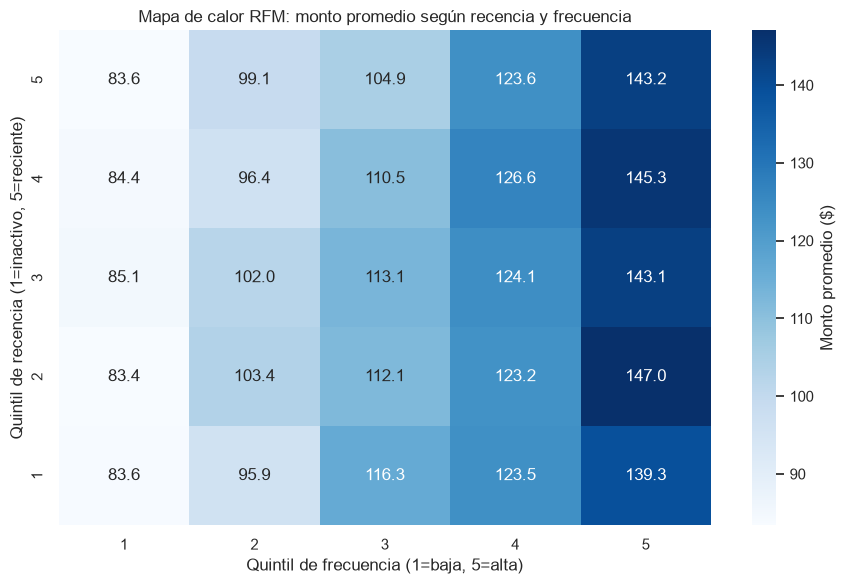

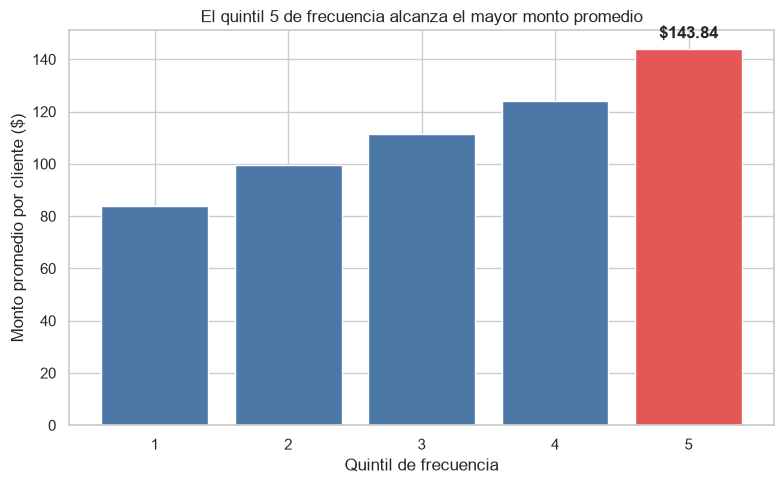

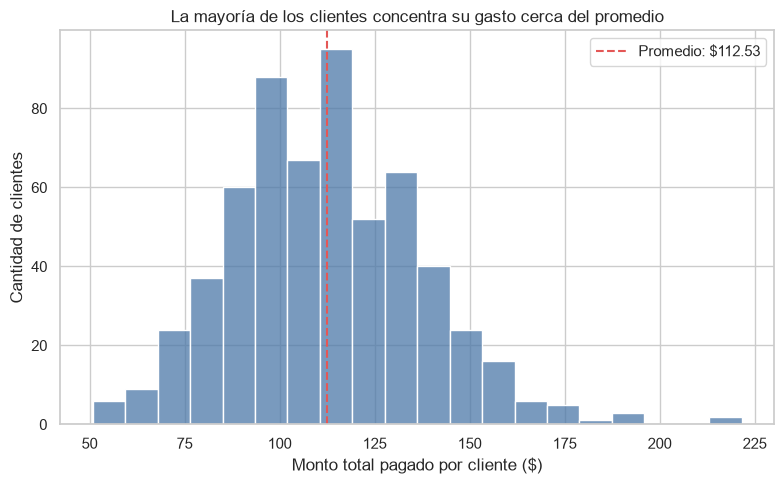

Hallazgo 1: el quintil 5 tiene el mayor monto promedio; priorizar fidelización.
Hallazgo 2: hay 19 clientes RFM=555; ofrecer beneficios de permanencia.
Hallazgo 3: 120 clientes son los menos recientes; evaluar reactivación segmentada.
Limitaciones: análisis histórico y descriptivo; no incorpora costos, preferencias ni prueba causalidad.


In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

GRAFICOS = RAIZ / "graficos"
GRAFICOS.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")

pivot_rfm = df_rfm.pivot_table(index="R_qcut", columns="F_qcut", values="monetary_amount", aggfunc="mean", observed=True).sort_index(ascending=False)
fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(pivot_rfm, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "Monto promedio ($)"}, ax=ax)
ax.set(title="Mapa de calor RFM: monto promedio según recencia y frecuencia", xlabel="Quintil de frecuencia (1=baja, 5=alta)", ylabel="Quintil de recencia (1=inactivo, 5=reciente)")
fig.tight_layout(); fig.savefig(GRAFICOS / "heatmap_rfm_monto.png", dpi=150); plt.show()

resumen_frecuencia = df_rfm.groupby("F_qcut", observed=True)["monetary_amount"].mean().sort_index()
destacado = int(resumen_frecuencia.idxmax())
fig, ax = plt.subplots(figsize=(8, 5))
barras = ax.bar(resumen_frecuencia.index.astype(str), resumen_frecuencia.values, color=["#E45756" if int(x)==destacado else "#4C78A8" for x in resumen_frecuencia.index])
barra = barras[list(resumen_frecuencia.index).index(destacado)]
ax.annotate(f"${barra.get_height():.2f}", (barra.get_x()+barra.get_width()/2, barra.get_height()), xytext=(0, 8), textcoords="offset points", ha="center", fontweight="bold")
ax.set(title=f"El quintil {destacado} de frecuencia alcanza el mayor monto promedio", xlabel="Quintil de frecuencia", ylabel="Monto promedio por cliente ($)")
fig.tight_layout(); fig.savefig(GRAFICOS / "monto_por_frecuencia_narrativo.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(df_rfm["monetary_amount"], bins=20, color="#4C78A8", ax=ax)
promedio = df_rfm["monetary_amount"].mean()
ax.axvline(promedio, color="#E45756", linestyle="--", label=f"Promedio: ${promedio:.2f}")
ax.set(title="La mayoría de los clientes concentra su gasto cerca del promedio", xlabel="Monto total pagado por cliente ($)", ylabel="Cantidad de clientes")
ax.legend(); fig.tight_layout(); fig.savefig(GRAFICOS / "distribucion_monto_clientes.png", dpi=150); plt.show()

campeones = (df_rfm["Segmento_RFM"] == "555").sum()
inactivos = (df_rfm["R_qcut"] == 1).sum()
print(f"Hallazgo 1: el quintil {destacado} tiene el mayor monto promedio; priorizar fidelización.")
print(f"Hallazgo 2: hay {campeones} clientes RFM=555; ofrecer beneficios de permanencia.")
print(f"Hallazgo 3: {inactivos} clientes son los menos recientes; evaluar reactivación segmentada.")
print("Limitaciones: análisis histórico y descriptivo; no incorpora costos, preferencias ni prueba causalidad.")
